In [1]:
import kagglehub
import pandas as pd

# Download latest version
path = kagglehub.dataset_download("uciml/horse-colic")

print("Path to dataset files:", path)

/home/yana/Документы/iris/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


100%|██████████| 11.0k/11.0k [00:00<00:00, 17.3MB/s]

Extracting files...
Path to dataset files: /home/yana/.cache/kagglehub/datasets/uciml/horse-colic/versions/1


In [5]:
df = pd.read_csv(path + '/horse.csv')
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 299 entries, 0 to 298
Data columns (total 28 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   surgery                299 non-null    str    
 1   age                    299 non-null    str    
 2   hospital_number        299 non-null    int64  
 3   rectal_temp            239 non-null    float64
 4   pulse                  275 non-null    float64
 5   respiratory_rate       241 non-null    float64
 6   temp_of_extremities    243 non-null    str    
 7   peripheral_pulse       230 non-null    str    
 8   mucous_membrane        252 non-null    str    
 9   capillary_refill_time  267 non-null    str    
 10  pain                   244 non-null    str    
 11  peristalsis            255 non-null    str    
 12  abdominal_distention   243 non-null    str    
 13  nasogastric_tube       195 non-null    str    
 14  nasogastric_reflux     193 non-null    str    
 15  nasogastric_reflu

In [ ]:
import io

buffer = io.StringIO()

df.info(buf=buffer)

s = buffer.getvalue()

with open('df_info.txt', 'w', encoding='utf-8') as f:
    f.write(s)


Пропуски в датасете

In [10]:
missing = df.isnull().sum()
print(missing)

surgery                    0
age                        0
hospital_number            0
rectal_temp               60
pulse                     24
respiratory_rate          58
temp_of_extremities       56
peripheral_pulse          69
mucous_membrane           47
capillary_refill_time     32
pain                      55
peristalsis               44
abdominal_distention      56
nasogastric_tube         104
nasogastric_reflux       106
nasogastric_reflux_ph    246
rectal_exam_feces        102
abdomen                  118
packed_cell_volume        29
total_protein             33
abdomo_appearance        165
abdomo_protein           198
outcome                    0
surgical_lesion            0
lesion_1                   0
lesion_2                   0
lesion_3                   0
cp_data                    0
dtype: int64


In [11]:
percents = missing/len(df)
print(percents)

surgery                  0.000000
age                      0.000000
hospital_number          0.000000
rectal_temp              0.200669
pulse                    0.080268
respiratory_rate         0.193980
temp_of_extremities      0.187291
peripheral_pulse         0.230769
mucous_membrane          0.157191
capillary_refill_time    0.107023
pain                     0.183946
peristalsis              0.147157
abdominal_distention     0.187291
nasogastric_tube         0.347826
nasogastric_reflux       0.354515
nasogastric_reflux_ph    0.822742
rectal_exam_feces        0.341137
abdomen                  0.394649
packed_cell_volume       0.096990
total_protein            0.110368
abdomo_appearance        0.551839
abdomo_protein           0.662207
outcome                  0.000000
surgical_lesion          0.000000
lesion_1                 0.000000
lesion_2                 0.000000
lesion_3                 0.000000
cp_data                  0.000000
dtype: float64


In [12]:
if 'hospital_number' in df.columns:
    unique_ids = df['hospital_number'].nunique()
    print(f"Уникальных hospital_number: {unique_ids}")

    # Проверка на дубликаты ID
    duplicates = df['hospital_number'].duplicated().sum()
    print(f"Строк с повторяющимся hospital_number: {duplicates}")

    # Если дубликаты есть, можно посмотреть, какие именно ID повторяются:
    if duplicates > 0:
        dup_ids = df[df['hospital_number'].duplicated(keep=False)]['hospital_number'].value_counts()
        print("\nПовторяющиеся ID (первые 10):")
        print(dup_ids.head(10))

Уникальных hospital_number: 283
Строк с повторяющимся hospital_number: 16

Повторяющиеся ID (первые 10):
hospital_number
530526    2
529796    2
528996    2
528890    2
529461    2
528904    2
528931    2
529424    2
528469    2
530693    2
Name: count, dtype: int64


In [ ]:
!pip install missingno

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 294.9/294.9 kB 1.2 MB/s eta 0:00:00a 0:00:01m

[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


<Axes: >

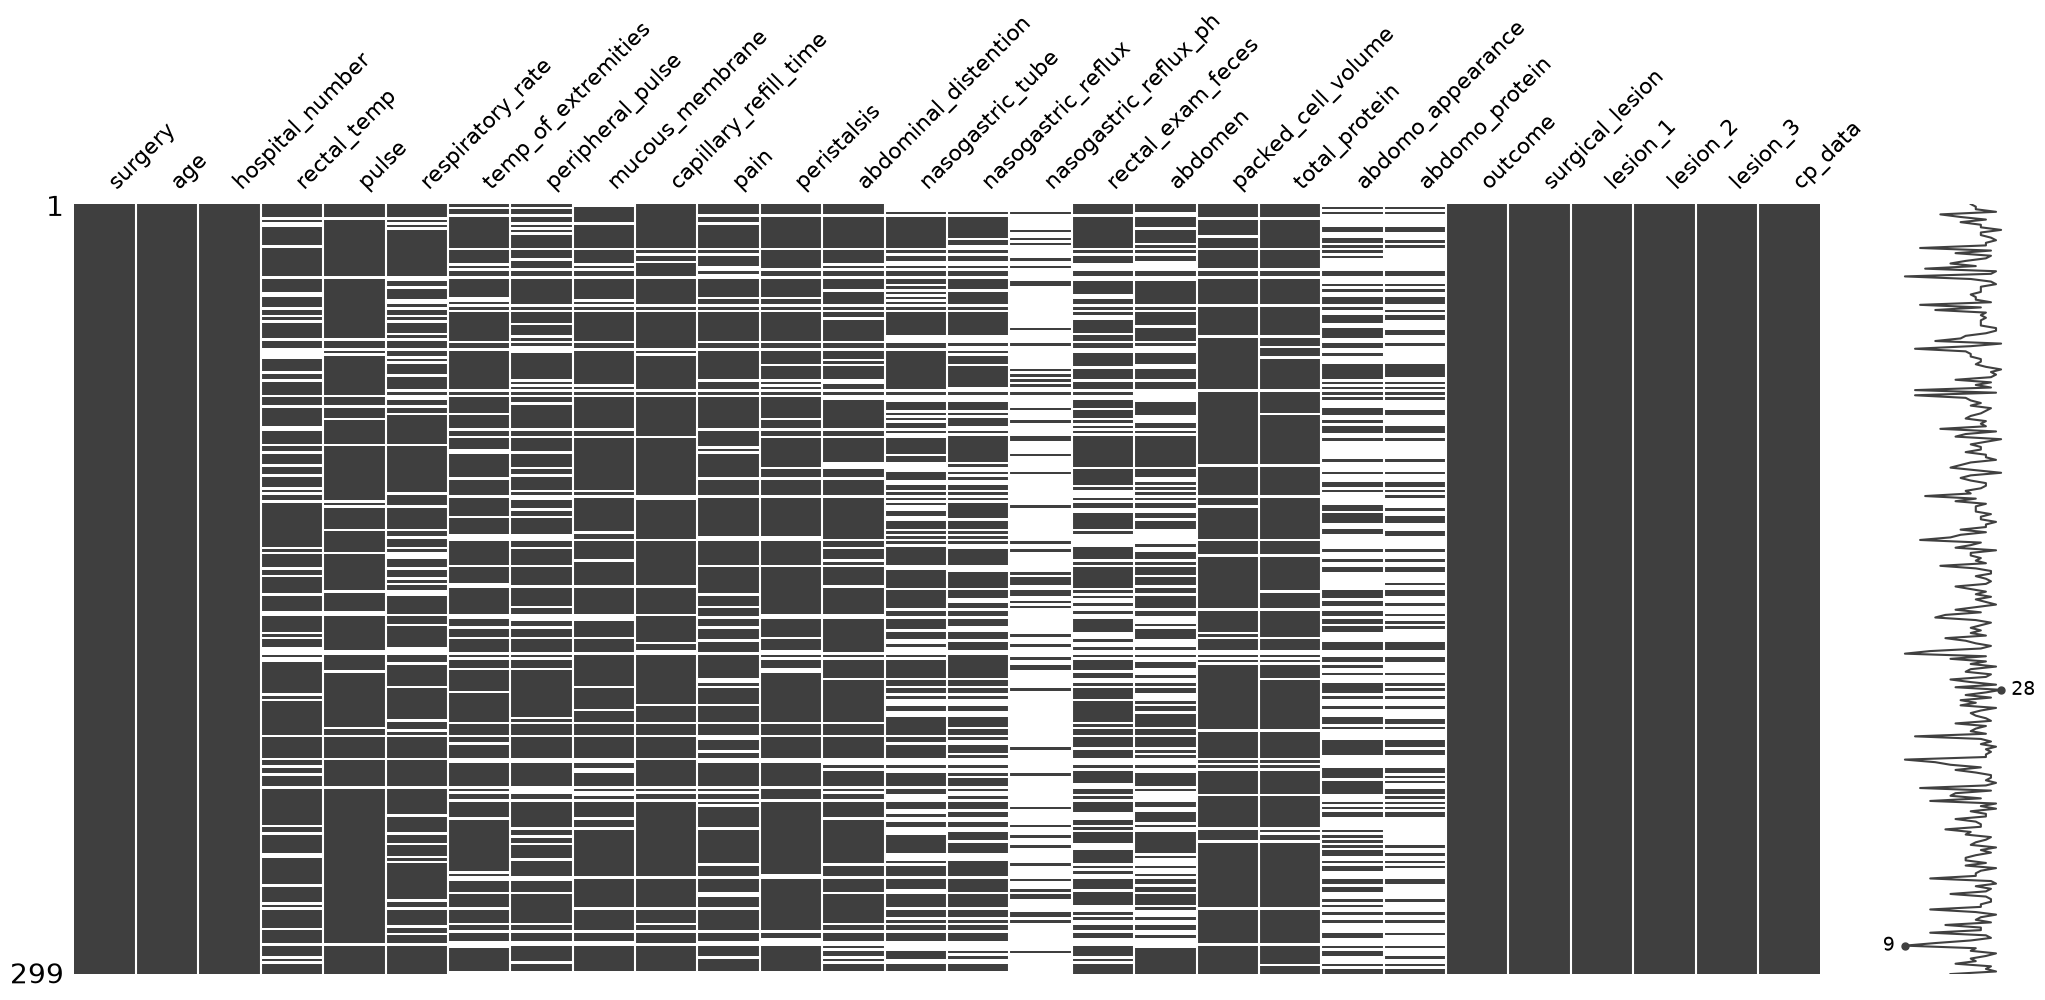

In [17]:
import missingno
missingno.matrix(df)

<Axes: >

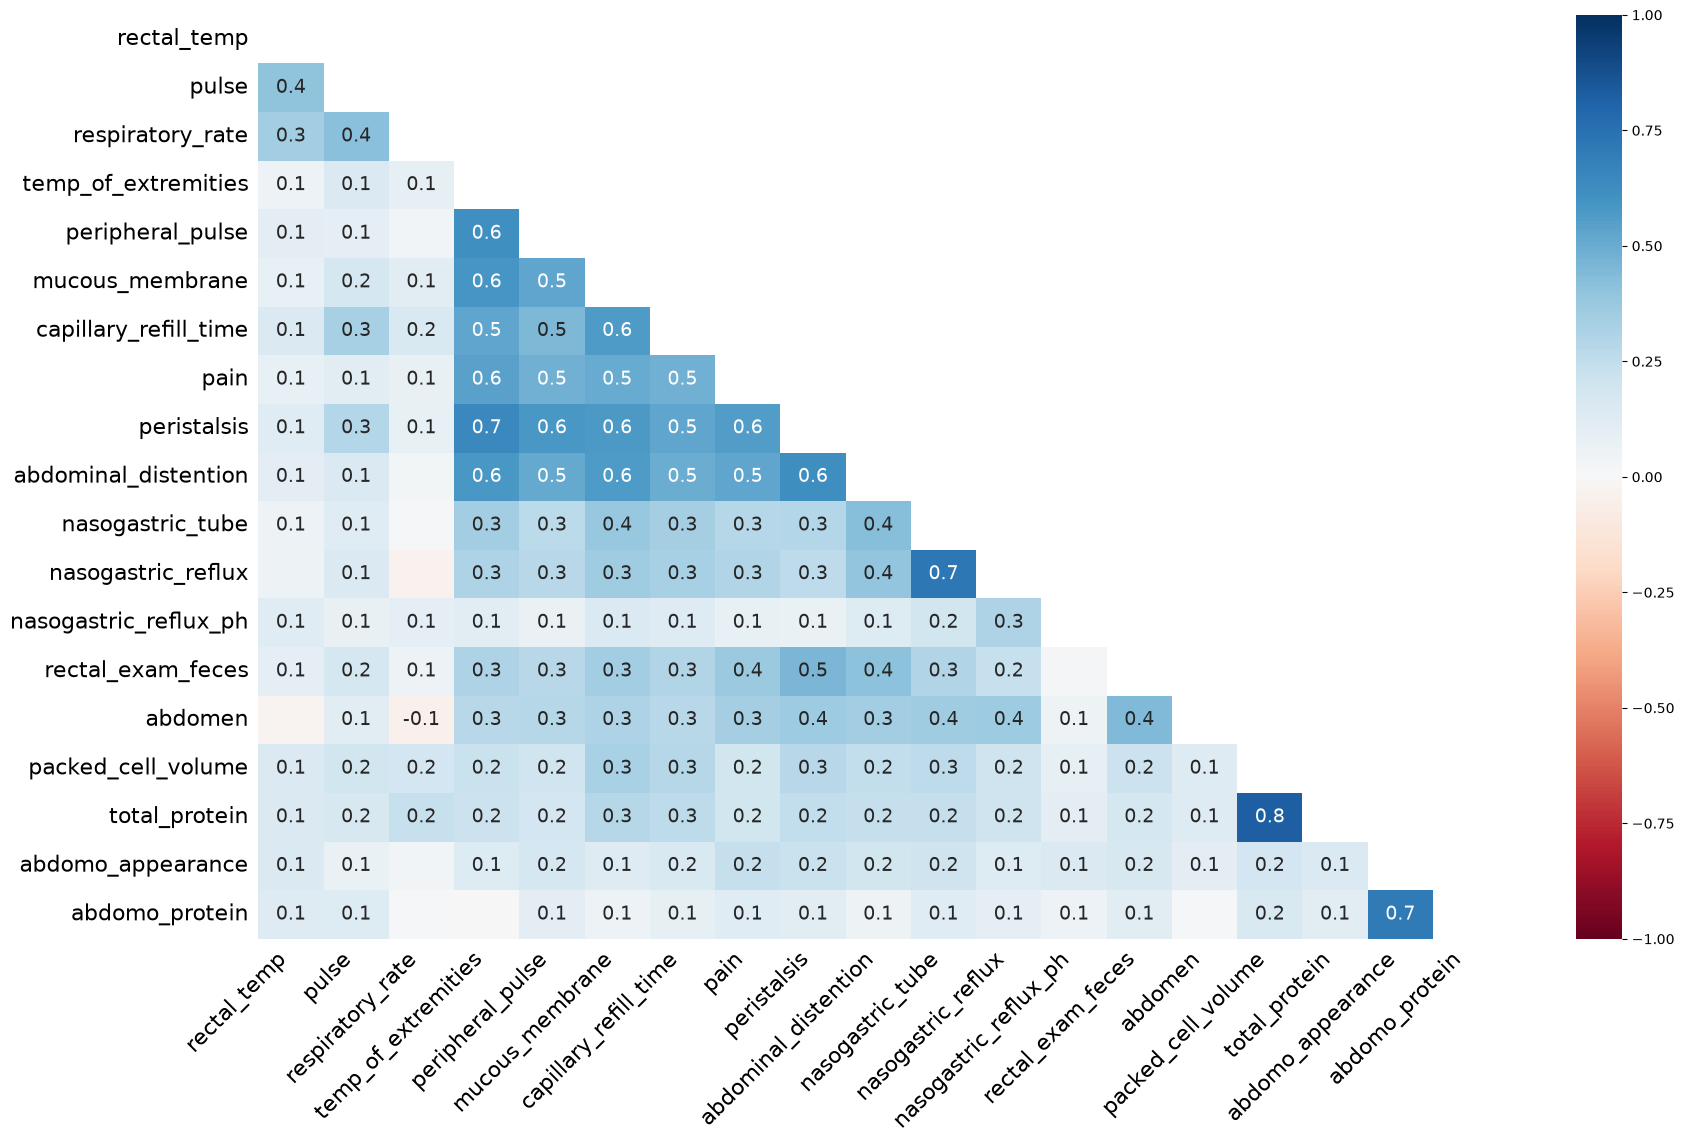

In [18]:
missingno.heatmap(df)

In [19]:
from scipy import stats

def mcar_test(df, target_col, test_col):
    """Сравниваем распределение test_col в группах: где target_col пропущен vs заполнен."""
    group_missing = df[df[target_col].isnull()][test_col].dropna()
    group_present = df[df[target_col].notnull()][test_col].dropna()

    # t-test для числовых, chi2 для категориальных
    if df[test_col].dtype in ['float64', 'int64']:
        stat, p = stats.ttest_ind(group_missing, group_present, equal_var=False)
        test_name = "t-test"
    else:
        # chi-square по таблице сопряжённости
        contingency = pd.crosstab(df[target_col].isnull(), df[test_col])
        stat, p, _, _ = stats.chi2_contingency(contingency)
        test_name = "chi2"

    print(f"{target_col} missing vs {test_col}: {test_name}, p = {p:.4f}")
    if p < 0.05:
        print("  → Распределения различаются. Не MCAR (вероятно MAR или MNAR).")
    else:
        print("  → Различий не обнаружено. Совместимо с MCAR.")

# Пример для Horse Colic
mcar_test(df, target_col='rectal_temp', test_col='pulse')
mcar_test(df, target_col='rectal_temp', test_col='age')

rectal_temp missing vs pulse: t-test, p = 0.0140
  → Распределения различаются. Не MCAR (вероятно MAR или MNAR).
rectal_temp missing vs age: chi2, p = 0.8666
  → Различий не обнаружено. Совместимо с MCAR.


In [20]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
import numpy as np

def mar_check(df, col_with_missing):
    # Целевая переменная: пропущено или нет
    y = df[col_with_missing].isnull().astype(int)

    # Признаки: все остальные числовые колонки
    X = df.drop(columns=[col_with_missing]).select_dtypes(include=[np.number])
    X = X.fillna(X.median())  # грубо, но для проверки сойдёт

    if y.nunique() < 2 or len(X.columns) == 0:
        print(f"{col_with_missing}: недостаточно данных для проверки")
        return

    clf = LogisticRegression(max_iter=1000)
    scores = cross_val_score(clf, X, y, cv=5, scoring='roc_auc')
    print(f"{col_with_missing}: AUC = {scores.mean():.3f} ± {scores.std():.3f}")
    if scores.mean() > 0.65:
        print("  → Пропуск предсказуем по другим признакам. Похоже на MAR.")
    else:
        print("  → Пропуск плохо предсказуем. Совместимо с MCAR.")

mar_check(df, 'rectal_temp')
mar_check(df, 'nasogastric_reflux_ph')

/home/yana/Документы/iris/.venv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


rectal_temp: AUC = 0.630 ± 0.032
  → Пропуск плохо предсказуем. Совместимо с MCAR.
nasogastric_reflux_ph: AUC = 0.562 ± 0.114
  → Пропуск плохо предсказуем. Совместимо с MCAR.


/home/yana/Документы/iris/.venv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [21]:
for col in df.columns:
    if df[col].isnull().sum() == 0:
        continue
    contingency = pd.crosstab(df[col].isnull(), df['outcome'])
    stat, p, _, _ = stats.chi2_contingency(contingency)
    if p < 0.05:
        print(f"{col}: пропуск связан с outcome (p={p:.4f}) → возможен MNAR")

rectal_temp: пропуск связан с outcome (p=0.0090) → возможен MNAR
pulse: пропуск связан с outcome (p=0.0396) → возможен MNAR
nasogastric_reflux_ph: пропуск связан с outcome (p=0.0494) → возможен MNAR
total_protein: пропуск связан с outcome (p=0.0400) → возможен MNAR
abdomo_protein: пропуск связан с outcome (p=0.0021) → возможен MNAR


In [24]:
LOG_FILE = 'horse_colic_eda_report.txt'
_log_handle = open(LOG_FILE, 'w', encoding='utf-8')

def log(*args, **kwargs):
    """Печатает в консоль и пишет в файл одновременно."""
    text = ' '.join(str(a) for a in args)
    print(text, **kwargs)
    _log_handle.write(text + '\n')

In [25]:
import pandas as pd
import numpy as np
from scipy import stats
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
from sklearn.preprocessing import LabelEncoder
import warnings
warnings.filterwarnings('ignore')


# ============================================================
# 1. ЗАГРУЗКА И ПОДГОТОВКА
# ============================================================
# Целевая переменная (для MNAR-теста). Укажите свою, если нужно.
TARGET = 'outcome'

df_enc = df.copy()
for col in df_enc.select_dtypes(include='object').columns:
    if col == TARGET:
        continue
    df_enc[col] = LabelEncoder().fit_transform(df_enc[col].astype(str))

if df_enc[TARGET].dtype == 'object':
    df_enc[TARGET] = LabelEncoder().fit_transform(df_enc[TARGET].astype(str))


# ============================================================
# 2. ВСПОМОГАТЕЛЬНЫЕ ФУНКЦИИ
# ============================================================

def mcar_test(df, col):
    mask_missing = df[col].isnull()
    if mask_missing.sum() < 5 or (~mask_missing).sum() < 5:
        return None
    p_values = []
    for other in df.select_dtypes(include=np.number).columns:
        if other == col:
            continue
        g1 = df.loc[mask_missing, other].dropna()
        g2 = df.loc[~mask_missing, other].dropna()
        if len(g1) < 5 or len(g2) < 5:
            continue
        try:
            _, p = stats.ttest_ind(g1, g2, equal_var=False)
            if not np.isnan(p):
                p_values.append(p)
        except Exception:
            continue
    if not p_values:
        return None
    return np.mean(np.array(p_values) < 0.05)


def mar_test(df_enc, col, target):
    y = df_enc[col].isnull().astype(int)
    if y.nunique() < 2 or y.sum() < 5:
        return None
    features = [c for c in df_enc.select_dtypes(include=np.number).columns
                if c != col and c != target]
    if not features:
        return None
    X = df_enc[features].fillna(df_enc[features].median())
    try:
        clf = LogisticRegression(max_iter=1000, class_weight='balanced')
        scores = cross_val_score(clf, X, y, cv=5, scoring='roc_auc')
        return scores.mean()
    except Exception:
        return None


def mnar_test(df, col, target):
    if target not in df.columns:
        return None
    mask = df[col].isnull()
    if mask.sum() < 5 or (~mask).sum() < 5:
        return None
    contingency = pd.crosstab(mask, df[target])
    if contingency.shape[0] < 2 or contingency.shape[1] < 2:
        return None
    try:
        _, p, _, _ = stats.chi2_contingency(contingency)
        return p
    except Exception:
        return None


# ============================================================
# 3. ЗАГОЛОВОК ОТЧЁТА
# ============================================================

log("=" * 70)
log("EDA-ОТЧЁТ: АНАЛИЗ ПРИРОДЫ ПРОПУСКОВ")
log(f"Датасет: Horse Colic | Строк: {df.shape[0]} | Колонок: {df.shape[1]}")
log("=" * 70)
log()

# Общая сводка по пропускам
log("-" * 70)
log("ОБЩАЯ СВОДКА ПРОПУСКОВ")
log("-" * 70)
miss_summary = df.isnull().sum()
miss_summary = miss_summary[miss_summary > 0].sort_values(ascending=False)
log(f"Колонок с пропусками: {len(miss_summary)} из {df.shape[1]}")
log(f"Всего пропущенных значений: {df.isnull().sum().sum()}")
log()
for col, n in miss_summary.items():
    log(f"  {col:35s} {n:4d}  ({n / len(df) * 100:5.1f}%)")
log()


# ============================================================
# 4. ОСНОВНОЙ ЦИКЛ
# ============================================================

log("-" * 70)
log("КЛАССИФИКАЦИЯ КАЖДОГО ПРИЗНАКА")
log("-" * 70)
log("MCAR_share_sig — доля признаков, распределения которых различаются (чем меньше, тем ближе к MCAR)")
log("MAR_AUC       — AUC предсказания факта пропуска по другим признакам (без target)")
log("MNAR_p        — p-value связи факта пропуска с целевой переменной")
log()

results = []

for col in df.columns:
    miss_ratio = df[col].isnull().mean()
    if miss_ratio == 0:
        continue

    if miss_ratio < 0.05 or miss_ratio > 0.95:
        results.append({
            'column': col,
            'miss_%': round(miss_ratio * 100, 1),
            'MCAR_share_sig': None,
            'MAR_AUC': None,
            'MNAR_p': None,
            'verdict': 'недостаточно данных для теста'
        })
        continue

    mcar_share = mcar_test(df, col)
    mar_auc = mar_test(df_enc, col, TARGET)
    mnar_p = mnar_test(df, col, TARGET)

    if mar_auc is not None and mar_auc > 0.65:
        verdict = 'MAR'
    elif mnar_p is not None and mnar_p < 0.05:
        verdict = 'MNAR'
    elif mcar_share is not None and mcar_share < 0.1:
        verdict = 'MCAR'
    else:
        verdict = 'неясно'

    results.append({
        'column': col,
        'miss_%': round(miss_ratio * 100, 1),
        'MCAR_share_sig': None if mcar_share is None else round(mcar_share, 2),
        'MAR_AUC': None if mar_auc is None else round(mar_auc, 3),
        'MNAR_p': None if mnar_p is None else round(mnar_p, 4),
        'verdict': verdict
    })

    log(f"[{verdict:8s}] {col:35s} miss={miss_ratio*100:5.1f}%  "
        f"MCAR_share={results[-1]['MCAR_share_sig']}  "
        f"MAR_AUC={results[-1]['MAR_AUC']}  "
        f"MNAR_p={results[-1]['MNAR_p']}")


# ============================================================
# 5. ИТОГОВАЯ ТАБЛИЦА
# ============================================================

res_df = pd.DataFrame(results).sort_values('miss_%', ascending=False)

log()
log("-" * 70)
log("ИТОГОВАЯ ТАБЛИЦА")
log("-" * 70)
log(res_df.to_string(index=False))


# ============================================================
# 6. РЕКОМЕНДАЦИИ
# ============================================================

log()
log("-" * 70)
log("РЕКОМЕНДАЦИИ ПО ОБРАБОТКЕ")
log("-" * 70)

for _, row in res_df.iterrows():
    col = row['column']
    v = row['verdict']
    m = row['miss_%']
    if v == 'MCAR':
        action = "можно заполнить медианой/модой или удалить строки"
    elif v == 'MAR':
        action = "заполнить MICE/по модели + создать индикатор пропуска"
    elif v == 'MNAR':
        action = "не заполнять наивно; анализировать пропуск как категорию"
    else:
        action = "проанализировать вручную"
    if m > 70:
        action += " | ВНИМАНИЕ: >70% пропусков, рассмотреть удаление колонки"
    log(f"  {col:35s} [{v:6s}] {m:5.1f}%  →  {action}")


# ============================================================
# 7. СВОДКА ПО ТИПАМ
# ============================================================

log()
log("-" * 70)
log("СВОДКА ПО ТИПАМ ПРОПУСКОВ")
log("-" * 70)
counts = res_df['verdict'].value_counts()
for verdict, n in counts.items():
    log(f"  {verdict:10s}: {n}")

log()
log("=" * 70)
log(f"Отчёт сохранён в файл: {LOG_FILE}")
log("=" * 70)

_log_handle.close()

EDA-ОТЧЁТ: АНАЛИЗ ПРИРОДЫ ПРОПУСКОВ
Датасет: Horse Colic | Строк: 299 | Колонок: 28

----------------------------------------------------------------------
ОБЩАЯ СВОДКА ПРОПУСКОВ
----------------------------------------------------------------------
Колонок с пропусками: 19 из 28
Всего пропущенных значений: 1602

  nasogastric_reflux_ph                246  ( 82.3%)
  abdomo_protein                       198  ( 66.2%)
  abdomo_appearance                    165  ( 55.2%)
  abdomen                              118  ( 39.5%)
  nasogastric_reflux                   106  ( 35.5%)
  nasogastric_tube                     104  ( 34.8%)
  rectal_exam_feces                    102  ( 34.1%)
  peripheral_pulse                      69  ( 23.1%)
  rectal_temp                           60  ( 20.1%)
  respiratory_rate                      58  ( 19.4%)
  temp_of_extremities                   56  ( 18.7%)
  abdominal_distention                  56  ( 18.7%)
  pain                                  55  ( 18.

In [27]:
!pip install statsmodels

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.1/12.1 MB 4.6 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 118.9/118.9 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 233.3/233.3 kB 2.4 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 239.8/239.8 kB 2.8 MB/s eta 0:00:0000:0100:01

[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


In [31]:
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.decomposition import PCA
from sklearn.feature_selection import mutual_info_classif
from statsmodels.stats.multitest import multipletests
import warnings
warnings.filterwarnings('ignore')
import os


# ============================================================
# 0. НАСТРОЙКИ
# ============================================================

SHOW_PLOTS = True          # показывать графики на экране
LOG_FILE = 'horse_colic_eda_stage2.txt'
PLOT_DIR = 'plots'
os.makedirs(PLOT_DIR, exist_ok=True)

# Определяем, есть ли GUI. Если нет — matplotlib уйдёт в Agg,
# и plt.show() просто ничего не сделает, ошибки не будет.
if not os.environ.get('DISPLAY') and os.name != 'nt':
    # Linux/macOS без DISPLAY → скорее всего headless
    # Но в Jupyter всё равно работает inline, поэтому не форсируем Agg
    pass

# Улучшаем стиль графиков
sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 100
plt.rcParams['savefig.dpi'] = 100
plt.rcParams['font.size'] = 10

_log_handle = open(LOG_FILE, 'w', encoding='utf-8')

def log(*args, **kwargs):
    text = ' '.join(str(a) for a in args)
    print(text, **kwargs)
    _log_handle.write(text + '\n')

def section(title):
    log()
    log("=" * 70)
    log(title)
    log("=" * 70)

def save_plot(name):
    """Сохраняет график в файл и показывает на экране (если SHOW_PLOTS)."""
    path = os.path.join(PLOT_DIR, f'{name}.png')
    plt.tight_layout()
    plt.savefig(path, dpi=100, bbox_inches='tight')
    log(f"  [график сохранён: {path}]")
    if SHOW_PLOTS:
        try:
            plt.show()
        except Exception as e:
            log(f"  [не удалось показать график: {e}]")
    plt.close()


# ============================================================
# 1. ЗАГРУЗКА
# ============================================================

TARGET = 'outcome'

log("=" * 70)
log("EDA ЭТАП 2: РАСПРЕДЕЛЕНИЯ, СВЯЗИ, ТЕСТЫ, PCA")
log(f"Датасет: Horse Colic | Строк: {df.shape[0]} | Колонок: {df.shape[1]}")
log("=" * 70)


# ============================================================
# 2. ТИПЫ ПРИЗНАКОВ
# ============================================================

section("1. ТИПЫ ПРИЗНАКОВ")

num_cols = df.select_dtypes(include=np.number).columns.tolist()
cat_cols = df.select_dtypes(include='object').columns.tolist()

if TARGET in num_cols:
    num_cols.remove(TARGET)
if TARGET in cat_cols:
    cat_cols.remove(TARGET)

log(f"Целевая переменная: {TARGET}")
log(f"Числовых признаков: {len(num_cols)}")
for c in num_cols:
    log(f"  - {c}")
log(f"Категориальных признаков: {len(cat_cols)}")
for c in cat_cols:
    log(f"  - {c}")

df_filled = df.copy()
for c in num_cols:
    df_filled[c] = df_filled[c].fillna(df_filled[c].median())
for c in cat_cols:
    df_filled[c] = df_filled[c].fillna(df_filled[c].mode()[0])
df_filled[TARGET] = df_filled[TARGET].fillna(df_filled[TARGET].mode()[0])


# ============================================================
# 3. ОДНОМЕРНЫЙ АНАЛИЗ
# ============================================================

section("2. ОДНОМЕРНЫЙ АНАЛИЗ: РАСПРЕДЕЛЕНИЯ")

log("\n--- Числовые признаки: описательные статистики ---")
desc = df_filled[num_cols].describe().T
desc['skew'] = df_filled[num_cols].skew()
desc['kurtosis'] = df_filled[num_cols].kurtosis()
log(desc.round(3).to_string())

# Гистограммы
n = len(num_cols)
ncols = 4
nrows = (n + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3 * nrows))
axes = axes.flatten() if n > 1 else [axes]
for i, col in enumerate(num_cols):
    axes[i].hist(df_filled[col], bins=25, color='steelblue', edgecolor='black')
    axes[i].set_title(col, fontsize=10)
for j in range(n, len(axes)):
    axes[j].axis('off')
save_plot('01_histograms_numeric')

# Boxplot'ы
fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3 * nrows))
axes = axes.flatten() if n > 1 else [axes]
for i, col in enumerate(num_cols):
    axes[i].boxplot(df_filled[col].dropna(), vert=True)
    axes[i].set_title(col, fontsize=10)
for j in range(n, len(axes)):
    axes[j].axis('off')
save_plot('02_boxplots_numeric')

log("\n--- Категориальные признаки: распределение значений ---")
for c in cat_cols:
    vc = df_filled[c].value_counts()
    log(f"\n{c}:")
    for val, cnt in vc.items():
        log(f"  {val:30s} {cnt:4d}  ({cnt / len(df_filled) * 100:5.1f}%)")

log(f"\n--- Целевая переменная: {TARGET} ---")
vc = df_filled[TARGET].value_counts()
for val, cnt in vc.items():
    log(f"  {val:30s} {cnt:4d}  ({cnt / len(df_filled) * 100:5.1f}%)")

# Barplot целевой переменной
fig, ax = plt.subplots(figsize=(8, 5))
vc.plot(kind='bar', ax=ax, color='steelblue', edgecolor='black')
ax.set_title(f'Распределение {TARGET}')
ax.set_ylabel('Количество')
plt.xticks(rotation=30, ha='right')
save_plot('03_target_distribution')


# ============================================================
# 4. ДВУМЕРНЫЙ АНАЛИЗ: КОРРЕЛЯЦИИ
# ============================================================

section("3. ДВУМЕРНЫЙ АНАЛИЗ: КОРРЕЛЯЦИИ")

spearman_corr = df_filled[num_cols].corr(method='spearman')

fig, ax = plt.subplots(figsize=(14, 12))
sns.heatmap(spearman_corr, cmap='coolwarm', center=0, annot=False,
            square=True, cbar_kws={'shrink': 0.8}, ax=ax)
ax.set_title('Spearman correlation (numeric features)')
save_plot('04_correlation_heatmap')

log("\n--- Сильные корреляции (|Spearman r| > 0.6) ---")
corr_pairs = []
for i in range(len(spearman_corr.columns)):
    for j in range(i + 1, len(spearman_corr.columns)):
        r = spearman_corr.iloc[i, j]
        if abs(r) > 0.6:
            corr_pairs.append((spearman_corr.columns[i],
                               spearman_corr.columns[j],
                               round(r, 3)))
if corr_pairs:
    corr_pairs.sort(key=lambda x: abs(x[2]), reverse=True)
    for a, b, r in corr_pairs:
        log(f"  {a:25s} × {b:25s} r = {r}")
else:
    log("  нет пар с |r| > 0.6")


# ============================================================
# 5. СВЯЗЬ С ЦЕЛЕВОЙ
# ============================================================

section("4. СВЯЗЬ ПРИЗНАКОВ С ЦЕЛЕВОЙ ПЕРЕМЕННОЙ")

log("\n--- Числовые признаки vs outcome (Kruskal-Wallis) ---")
kw_results = []
for col in num_cols:
    groups = [g[col].dropna() for _, g in df_filled.groupby(TARGET)]
    groups = [g for g in groups if len(g) > 0]
    if len(groups) < 2:
        continue
    try:
        stat, p = stats.kruskal(*groups)
        kw_results.append({'feature': col, 'p_value': p, 'stat': stat})
    except Exception:
        continue

kw_df = pd.DataFrame(kw_results).sort_values('p_value')
if len(kw_df) > 0:
    _, p_adj, _, _ = multipletests(kw_df['p_value'], method='fdr_bh')
    kw_df['p_adj'] = p_adj
    kw_df['significant'] = kw_df['p_adj'] < 0.05
    log(kw_df.round(4).to_string(index=False))

top_num = kw_df.head(8)['feature'].tolist() if len(kw_df) > 0 else []
if top_num:
    fig, axes = plt.subplots(2, 4, figsize=(18, 8))
    axes = axes.flatten()
    for i, col in enumerate(top_num):
        sns.boxplot(x=TARGET, y=col, data=df_filled, ax=axes[i])
        axes[i].set_title(col, fontsize=10)
        axes[i].tick_params(axis='x', rotation=30)
    for j in range(len(top_num), len(axes)):
        axes[j].axis('off')
    save_plot('05_top_features_by_outcome')

log("\n--- Категориальные признаки vs outcome (chi2) ---")
chi_results = []
for col in cat_cols:
    contingency = pd.crosstab(df_filled[col], df_filled[TARGET])
    if contingency.shape[0] < 2 or contingency.shape[1] < 2:
        continue
    try:
        chi2, p, dof, _ = stats.chi2_contingency(contingency)
        n_total = contingency.sum().sum()
        v = np.sqrt(chi2 / (n_total * (min(contingency.shape) - 1)))
        chi_results.append({'feature': col, 'chi2': chi2, 'p_value': p,
                            'cramers_v': v})
    except Exception:
        continue

chi_df = pd.DataFrame(chi_results).sort_values('p_value')
if len(chi_df) > 0:
    _, p_adj, _, _ = multipletests(chi_df['p_value'], method='fdr_bh')
    chi_df['p_adj'] = p_adj
    chi_df['significant'] = chi_df['p_adj'] < 0.05
    log(chi_df.round(4).to_string(index=False))


# ============================================================
# 6. MUTUAL INFORMATION
# ============================================================

section("5. MUTUAL INFORMATION (все признаки)")

df_enc = df_filled.copy()
for c in df_enc.select_dtypes(include='object').columns:
    df_enc[c] = LabelEncoder().fit_transform(df_enc[c].astype(str))

X = df_enc.drop(columns=[TARGET])
y = df_enc[TARGET]

mi = mutual_info_classif(X, y, random_state=42)
mi_series = pd.Series(mi, index=X.columns).sort_values(ascending=False)

log("\nРанжирование признаков по mutual information:")
for col, val in mi_series.items():
    log(f"  {col:35s} MI = {val:.4f}")

fig, ax = plt.subplots(figsize=(10, 10))
mi_series.plot(kind='barh', ax=ax, color='steelblue')
ax.invert_yaxis()
ax.set_xlabel('Mutual Information')
ax.set_title('Feature importance by Mutual Information')
save_plot('06_mutual_information')


# ============================================================
# 7. PCA
# ============================================================

section("6. PCA (на числовых признаках)")

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_filled[num_cols])

pca = PCA()
X_pca = pca.fit_transform(X_scaled)

explained = pca.explained_variance_ratio_
cumulative = np.cumsum(explained)

log("\nОбъяснённая дисперсия по компонентам:")
for i, (e, c) in enumerate(zip(explained, cumulative)):
    log(f"  PC{i+1}: {e*100:5.2f}%  (накопл. {c*100:5.2f}%)")
    if i >= 9:
        log("  ...")
        break

n80 = np.argmax(cumulative >= 0.8) + 1
n90 = np.argmax(cumulative >= 0.9) + 1
log(f"\nКомпонент для 80% дисперсии: {n80}")
log(f"Компонент для 90% дисперсии: {n90}")

fig, ax = plt.subplots(figsize=(10, 6))
ax.bar(range(1, len(explained) + 1), explained * 100, alpha=0.7, label='Отдельная')
ax.plot(range(1, len(explained) + 1), cumulative * 100, 'ro-', label='Накопленная')
ax.axhline(80, color='gray', linestyle='--', alpha=0.5)
ax.set_xlabel('Компонента')
ax.set_ylabel('Дисперсия, %')
ax.set_title('PCA: объяснённая дисперсия')
ax.legend()
save_plot('07_pca_scree')

loadings = pd.DataFrame(
    pca.components_[:3].T,
    columns=['PC1', 'PC2', 'PC3'],
    index=num_cols
)
log("\nЗагрузки первых трёх компонент (топ по |значению|):")
for pc in ['PC1', 'PC2', 'PC3']:
    log(f"\n{pc}:")
    top = loadings[pc].abs().sort_values(ascending=False).head(5)
    for feat, _ in top.items():
        log(f"  {feat:30s} {loadings.loc[feat, pc]:+.3f}")

fig, ax = plt.subplots(figsize=(10, 8))
for cls in df_filled[TARGET].unique():
    mask = df_filled[TARGET] == cls
    ax.scatter(X_pca[mask, 0], X_pca[mask, 1], label=str(cls), alpha=0.6, s=30)
ax.set_xlabel(f'PC1 ({explained[0]*100:.1f}%)')
ax.set_ylabel(f'PC2 ({explained[1]*100:.1f}%)')
ax.set_title('PCA: проекция на первые 2 компоненты')
ax.legend()
save_plot('08_pca_scatter')


# ============================================================
# 8. ВЫВОДЫ
# ============================================================

section("7. КРАТКИЕ ВЫВОДЫ")

log("\nТоп-5 признаков по Kruskal-Wallis (числовые):")
if len(kw_df) > 0:
    for _, row in kw_df.head(5).iterrows():
        log(f"  {row['feature']:30s} p_adj = {row['p_adj']:.4f}")

log("\nТоп-5 признаков по chi2 (категориальные):")
if len(chi_df) > 0:
    for _, row in chi_df.head(5).iterrows():
        log(f"  {row['feature']:30s} p_adj = {row['p_adj']:.4f}  "
            f"Cramér's V = {row['cramers_v']:.3f}")

log("\nТоп-5 признаков по mutual information:")
for col, val in mi_series.head(5).items():
    log(f"  {col:30s} MI = {val:.4f}")

log(f"\nPCA: {n80} компонент объясняют 80% дисперсии")

log()
log("=" * 70)
log(f"Отчёт сохранён: {LOG_FILE}")
log(f"Графики сохранены в папке: {PLOT_DIR}/")
log("=" * 70)

_log_handle.close()

EDA ЭТАП 2: РАСПРЕДЕЛЕНИЯ, СВЯЗИ, ТЕСТЫ, PCA
Датасет: Horse Colic | Строк: 299 | Колонок: 28

1. ТИПЫ ПРИЗНАКОВ
Целевая переменная: outcome
Числовых признаков: 11
  - hospital_number
  - rectal_temp
  - pulse
  - respiratory_rate
  - nasogastric_reflux_ph
  - packed_cell_volume
  - total_protein
  - abdomo_protein
  - lesion_1
  - lesion_2
  - lesion_3
Категориальных признаков: 16
  - surgery
  - age
  - temp_of_extremities
  - peripheral_pulse
  - mucous_membrane
  - capillary_refill_time
  - pain
  - peristalsis
  - abdominal_distention
  - nasogastric_tube
  - nasogastric_reflux
  - rectal_exam_feces
  - abdomen
  - abdomo_appearance
  - surgical_lesion
  - cp_data

2. ОДНОМЕРНЫЙ АНАЛИЗ: РАСПРЕДЕЛЕНИЯ

--- Числовые признаки: описательные статистики ---
                       count         mean          std       min       25%       50%       75%        max    skew  kurtosis
hospital_number        299.0  1087732.702  1532031.582  518476.0  528904.0  530301.0  534736.0  5305629.0   2.